# Red neuronal para predecir la aprobación de estudiantes

# Librerías

In [53]:
from pathlib import Path
import os
import platform
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.random.set_seed(SEMILLA)

# Características de la máquina

| Característica | Valor |
|---|---|
| Sistema operativo | Windows |
| Versión del sistema | 11 |
| Procesador | AMD64 Family 25 Model 117 Stepping 2, AuthenticAMD |
| Núcleos lógicos | 16 |
| Memoria RAM | 31.31 GB |
| Python | 3.12.10 |
| TensorFlow | 2.21.0 |
| CPU detectada por TensorFlow | `/physical_device:CPU:0` |
| GPU detectada por TensorFlow | No detectada; se utilizará CPU |


# Lectura de datos

In [54]:
df = pd.read_csv('../data/DataSet-Estudiantes.csv') 
df.head()

,escuela,sexo,edad,ambito,grupo_familiar,estado_padres,educ_madre,educ_padre,trabajo_madre,trabajo_padre,...,rel_familia,tiempo_libre,sale_con_amigos,alcohol_diario,alcohol_semanal,salud,ausencias,nota_1er_parcial,nota_2do_parcial,nota_final
0,GP,F,18,urbano,mas de 3,separados,universitaria,universitaria,desde casa,educacion,...,buena,mas o menos,mucho,muy poco,muy poco,mas o menos,6,5,6,6
1,GP,F,17,urbano,mas de 3,NaN,primaria (hasta 4to),primaria (hasta 4to),desde casa,NaN,...,muy buena,mas o menos,mas o menos,muy poco,muy poco,mas o menos,4,5,5,6
2,GP,F,15,urbano,menos de 3,juntos,primaria (hasta 4to),primaria (hasta 4to),desde casa,otro,...,buena,mas o menos,poco,poco,mas o menos,mas o menos,10,7,8,10
3,GP,F,15,urbano,mas de 3,NaN,universitaria,primaria (hasta 9no),salud,servicios publicos,...,mas o menos,poco,poco,muy poco,muy poco,muy buena,2,15,14,15
4,GP,F,16,urbano,mas de 3,NaN,secundaria,secundaria,otro,NaN,...,buena,mas o menos,poco,muy poco,poco,muy buena,4,6,10,10


# Exploración inicial

In [55]:
resumen = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'faltantes': df.isna().sum(),
    'valores_unicos': df.nunique(dropna=True),
})
resumen

,tipo,faltantes,valores_unicos
escuela,str,0,2
sexo,str,0,2
edad,int64,0,8
ambito,str,0,2
grupo_familiar,str,0,2
estado_padres,str,175,2
educ_madre,str,0,5
educ_padre,str,0,5
trabajo_madre,str,0,5
trabajo_padre,str,97,5


count    1044.000000
mean       11.341954
std         3.864796
min         0.000000
25%        10.000000
50%        11.000000
75%        14.000000
max        20.000000
Name: nota_final, dtype: float64


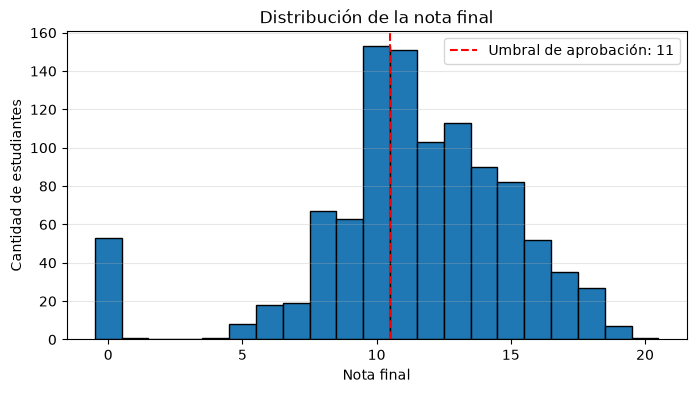

In [56]:
print(df['nota_final'].describe())

plt.figure(figsize=(8, 4))
plt.hist(df['nota_final'], bins=np.arange(-0.5, 21.5, 1), edgecolor='black')
plt.axvline(10.5, color='red', linestyle='--', label='Umbral de aprobación: 11')
plt.title('Distribución de la nota final')
plt.xlabel('Nota final')
plt.ylabel('Cantidad de estudiantes')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

# Separación de X e Y

La etiqueta `Y` se obtiene de `nota_final`: vale 1 cuando la nota es mayor o igual a 11 y 0 en caso contrario. Después se eliminan de `X` la nota final y las dos notas parciales, por lo que ninguna calificación se utiliza para entrenar el modelo.

In [57]:
columnas_excluidas = ['nota_final', 'nota_1er_parcial', 'nota_2do_parcial']
X = df.drop(columns=columnas_excluidas).copy()
Y = (df['nota_final'] >= 11).astype(np.float32)

print(f'Variables de entrada utilizadas: {X.shape[1]}')
print(f'Columnas excluidas: {columnas_excluidas}')
distribucion = Y.value_counts().sort_index().rename(index={0.0: 'No aprobado', 1.0: 'Aprobado'})
print(distribucion)
print(f'Porcentaje de aprobación: {Y.mean():.2%}')

Variables de entrada utilizadas: 30
Columnas excluidas: ['nota_final', 'nota_1er_parcial', 'nota_2do_parcial']
nota_final
No aprobado    383
Aprobado       661
Name: count, dtype: int64
Porcentaje de aprobación: 63.31%


# División de datos: entrenamiento, validación y prueba

Se utiliza una proporción aproximada de 64 % para entrenamiento, 16 % para validación y 20 % para prueba. La estratificación conserva la proporción de aprobados en cada conjunto.

In [58]:
X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=SEMILLA, stratify=Y
)
X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.20, random_state=SEMILLA, stratify=Y_temp
)

print('Entrenamiento:', X_train.shape, Y_train.shape)
print('Validación:   ', X_val.shape, Y_val.shape)
print('Prueba:       ', X_test.shape, Y_test.shape)

Entrenamiento: (668, 30) (668,)
Validación:    (167, 30) (167,)
Prueba:        (209, 30) (209,)


# Preprocesamiento de datos

Las columnas numéricas se completan con la mediana y se estandarizan. Las categóricas se completan con el valor más frecuente y se transforman mediante codificación one-hot. El preprocesador se ajusta solo con el conjunto de entrenamiento para evitar fuga de información.

In [59]:
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()
columnas_categoricas = X_train.select_dtypes(exclude=np.number).columns.tolist()

pipeline_numerico = Pipeline([
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler()),
])

# Compatibilidad con versiones antiguas y recientes de scikit-learn.
try:
    codificador = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    codificador = OneHotEncoder(handle_unknown='ignore', sparse=False)

pipeline_categorico = Pipeline([
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('codificador', codificador),
])

preprocesador = ColumnTransformer([
    ('numericas', pipeline_numerico, columnas_numericas),
    ('categoricas', pipeline_categorico, columnas_categoricas),
])

X_train_proc = preprocesador.fit_transform(X_train).astype(np.float32)
X_val_proc = preprocesador.transform(X_val).astype(np.float32)
X_test_proc = preprocesador.transform(X_test).astype(np.float32)

print(f'Columnas numéricas: {len(columnas_numericas)}')
print(f'Columnas categóricas: {len(columnas_categoricas)}')
print(f'Características después del preprocesamiento: {X_train_proc.shape[1]}')

Columnas numéricas: 3
Columnas categóricas: 27
Características después del preprocesamiento: 94


# Red neuronal profunda

In [60]:
class MLP(tf.keras.Model):
    def __init__(self):
        super().__init__()
        self.capa_oculta1 = tf.keras.layers.Dense(64, activation='relu', name='capa_oculta1')
        self.dropout1 = tf.keras.layers.Dropout(0.20)
        self.capa_oculta2 = tf.keras.layers.Dense(32, activation='relu', name='capa_oculta2')
        self.dropout2 = tf.keras.layers.Dropout(0.10)
        self.capa_salida = tf.keras.layers.Dense(1, activation='sigmoid', name='capa_salida')

    def call(self, entradas, training=False):
        x = self.capa_oculta1(entradas)
        x = self.dropout1(x, training=training)
        x = self.capa_oculta2(x)
        x = self.dropout2(x, training=training)
        return self.capa_salida(x)

# Crear y entrenar el modelo

In [61]:
tf.keras.backend.clear_session()
modelo = MLP()
modelo(tf.zeros((1, X_train_proc.shape[1]), dtype=tf.float32))

optimizador = tf.keras.optimizers.Adam(learning_rate=0.001)
modelo.compile(
    optimizer=optimizador,
    loss='binary_crossentropy',
    metrics=['accuracy'],
)
modelo.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta1 (Dense)            │ (1, 64)                │         6,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta2 (Dense)            │ (1, 32)                │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_salida (Dense)             │ (1, 1)                 │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,193 (32.00 KB)

 Trainable params: 8,193 (32.00 KB)

 Non-trainable params: 0 (0.00 B)

In [62]:
detencion_temprana = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
)

historial = modelo.fit(
    X_train_proc,
    Y_train.to_numpy(dtype=np.float32),
    validation_data=(X_val_proc, Y_val.to_numpy(dtype=np.float32)),
    epochs=150,
    batch_size=32,
    callbacks=[detencion_temprana],
    verbose=1,
)

Epoch 1/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5853 - loss: 0.6700 - val_accuracy: 0.6407 - val_loss: 0.6363
Epoch 2/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6572 - loss: 0.6201 - val_accuracy: 0.6826 - val_loss: 0.6113
Epoch 3/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6886 - loss: 0.5800 - val_accuracy: 0.7126 - val_loss: 0.5963
Epoch 4/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7275 - loss: 0.5613 - val_accuracy: 0.7186 - val_loss: 0.5856
Epoch 5/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7485 - loss: 0.5290 - val_accuracy: 0.7066 - val_loss: 0.5826
Epoch 6/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7470 - loss: 0.5108 - val_accuracy: 0.7246 - val_loss: 0.5879
Epoch 7/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7500 - loss: 0.5009 - val_accuracy: 0.6946 - val_loss: 0.5932
Epoch 8/150
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7635 - loss: 0.4867 - val_accuracy: 0.6946 - v

# Gráficas de pérdida y precisión

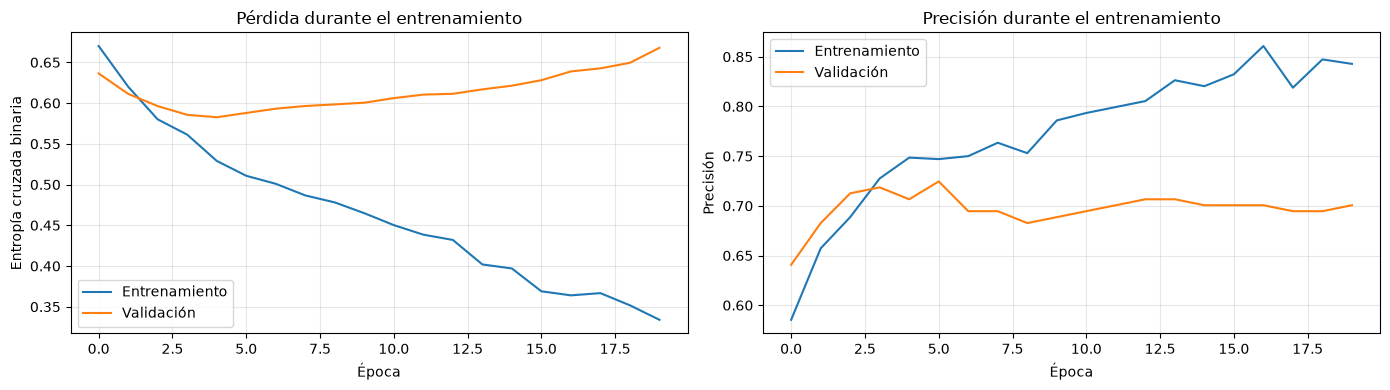

In [63]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))

ejes[0].plot(historial.history['loss'], label='Entrenamiento')
ejes[0].plot(historial.history['val_loss'], label='Validación')
ejes[0].set_title('Pérdida durante el entrenamiento')
ejes[0].set_xlabel('Época')
ejes[0].set_ylabel('Entropía cruzada binaria')
ejes[0].legend()
ejes[0].grid(True, alpha=0.3)

ejes[1].plot(historial.history['accuracy'], label='Entrenamiento')
ejes[1].plot(historial.history['val_accuracy'], label='Validación')
ejes[1].set_title('Precisión durante el entrenamiento')
ejes[1].set_xlabel('Época')
ejes[1].set_ylabel('Precisión')
ejes[1].legend()
ejes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluación del modelo

In [64]:
perdida_test, precision_test = modelo.evaluate(
    X_test_proc, Y_test.to_numpy(dtype=np.float32), verbose=0
)
print(f'Pérdida en prueba: {perdida_test:.4f}')
print(f'Precisión en prueba: {precision_test:.4f}')

Pérdida en prueba: 0.5547
Precisión en prueba: 0.7416


# Matriz de confusión y reporte de clasificación

Matriz de confusión:
[[ 35  42]
 [ 12 120]]
Exactitud calculada: 0.7416


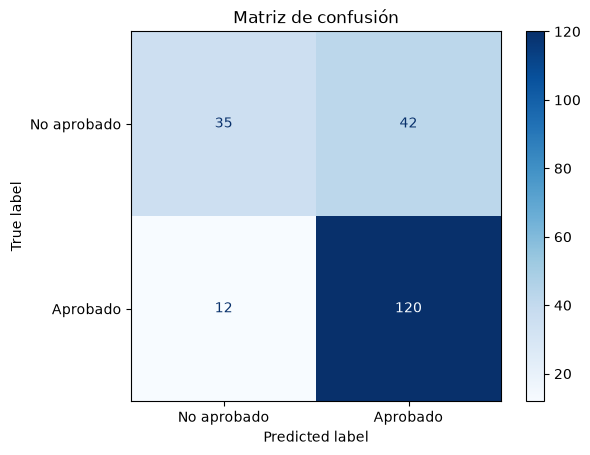

Reporte de clasificación:
              precision    recall  f1-score   support

 No aprobado     0.7447    0.4545    0.5645        77
    Aprobado     0.7407    0.9091    0.8163       132

    accuracy                         0.7416       209
   macro avg     0.7427    0.6818    0.6904       209
weighted avg     0.7422    0.7416    0.7236       209



In [65]:
probabilidades = modelo.predict(X_test_proc, verbose=0).ravel()
Y_pred = (probabilidades >= 0.5).astype(int)
Y_test_int = Y_test.to_numpy(dtype=int)

matriz = confusion_matrix(Y_test_int, Y_pred)
print('Matriz de confusión:')
print(matriz)
print(f'Exactitud calculada: {accuracy_score(Y_test_int, Y_pred):.4f}')

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['No aprobado', 'Aprobado'],
).plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión')
plt.show()

print('Reporte de clasificación:')
print(classification_report(
    Y_test_int,
    Y_pred,
    target_names=['No aprobado', 'Aprobado'],
    digits=4,
))

# Ejemplos de predicción

La siguiente tabla compara algunas predicciones del conjunto de prueba con su clase real.

In [66]:
ejemplos = X_test.head(10).copy()
ejemplos['clase_real'] = Y_test.head(10).map({0.0: 'No aprobado', 1.0: 'Aprobado'}).to_numpy()
ejemplos['probabilidad_aprobar'] = probabilidades[:10]
ejemplos['prediccion'] = np.where(Y_pred[:10] == 1, 'Aprobado', 'No aprobado')
ejemplos[[
    'edad', 'tiempo_estudio', 'asignaturas_perdidas', 'ausencias',
    'clase_real', 'probabilidad_aprobar', 'prediccion'
]]

,edad,tiempo_estudio,asignaturas_perdidas,ausencias,clase_real,probabilidad_aprobar,prediccion
1006,18,5 a 10 horas,0,5,Aprobado,0.730972,Aprobado
749,18,2 a 5 horas,0,2,Aprobado,0.791587,Aprobado
696,18,2 a 5 horas,0,2,Aprobado,0.695604,Aprobado
892,17,mas de 10 horas,1,0,No aprobado,0.273915,No aprobado
610,16,2 a 5 horas,0,4,Aprobado,0.507879,Aprobado
323,17,5 a 10 horas,0,1,Aprobado,0.799034,Aprobado
456,16,menos de 2 horas,0,0,Aprobado,0.557785,Aprobado
530,16,menos de 2 horas,0,12,Aprobado,0.800694,Aprobado
48,15,2 a 5 horas,0,2,Aprobado,0.623992,Aprobado
89,16,2 a 5 horas,0,18,No aprobado,0.525935,Aprobado


## Conclusión

La precisión, la matriz de confusión y el reporte de clasificación permiten evaluar el desempeño de la red en datos que no se utilizaron para entrenarla. En este experimento el modelo no recibe ninguna nota como entrada: predice utilizando únicamente las características personales, familiares, académicas y sociales disponibles. Por ello es normal obtener una precisión menor que con un modelo que sí conoce las notas parciales.